# Induction heads in GPT-2 small — reproduction + a cross-linguistic check

Reproduces the core induction-head result from Olsson et al. (2022),
[*In-context Learning and Induction Heads*](https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html),
then asks whether the same heads do the work on repeated **English, Spanish, German and Swedish** text —
controlling for the fact that GPT-2's tokenizer splits non-English words into many more pieces.

Helpers live in [`induction.py`](induction.py). The write-up with results is in the [README](README.md).

Sequence layout throughout: `[BOS, x_1 … x_L, x_1 … x_L]`. Losses are scored on L−1 predictions per copy;
in the second copy every one of them can be solved by induction.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

import induction as ind

FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

COLORS = {"en": "#2a78d6", "es": "#eb6834", "de": "#1baf7a", "sv": "#eda100", "random": "#8a8985"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
})

torch.manual_seed(0)
model = ind.load_model("gpt2-small")
L, BATCH, SEED, N_RANDOM_DRAWS = 50, 20, 0, 10
summary = {"config": {"model": "gpt2-small", "L": L, "batch": BATCH, "seed": SEED}}

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2-small into HookedTransformer


## 1. Repeated random tokens: per-token loss

20 sequences of 50 uniformly random tokens, each repeated once. The first copy is unpredictable;
the second copy should be nearly free if the model can copy from context.

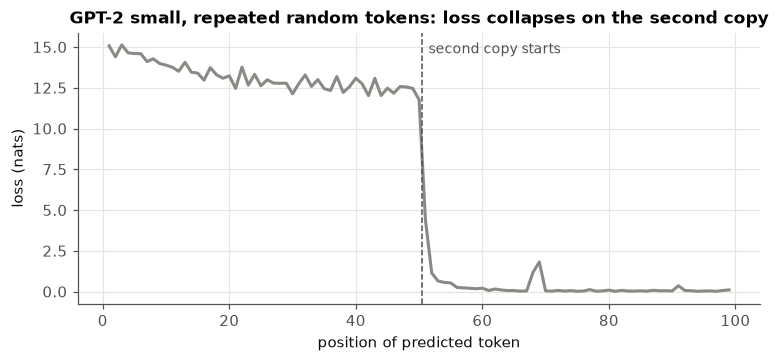

first copy 13.20 nats · second copy 0.28 nats · gain 12.93


In [2]:
rand = ind.random_tokens(model, L, BATCH, SEED)
rand_loss = ind.per_token_loss(model, rand)
rand_clean = ind.loss_summary(rand_loss, L)

fig, ax = plt.subplots(figsize=(8, 3.2))
pos = np.arange(1, 2 * L)               # target positions 2 .. 2L
ax.plot(pos, rand_loss.mean(0)[1:], color=COLORS["random"])
ax.axvline(L + 0.5, color=MUTED, lw=1, ls="--")
ax.text(L + 1.5, ax.get_ylim()[1] * 0.92, "second copy starts", color=MUTED, fontsize=9)
ax.set(xlabel="position of predicted token", ylabel="loss (nats)",
       title="GPT-2 small, repeated random tokens: loss collapses on the second copy")
fig.savefig(FIG / "1_random_tokens_loss.png"); plt.show()

print(f"first copy {rand_clean.first:.2f} nats · second copy {rand_clean.second:.2f} nats · gain {rand_clean.gain:.2f}")
summary["random_tokens"] = {"first": rand_clean.first, "second": rand_clean.second, "gain": rand_clean.gain}

## 2. Induction score per head

For each head, mean attention from position *q* in the second copy to *q − L + 1* —
the token right after the earlier occurrence of the current token (*q − 49* for L = 50).

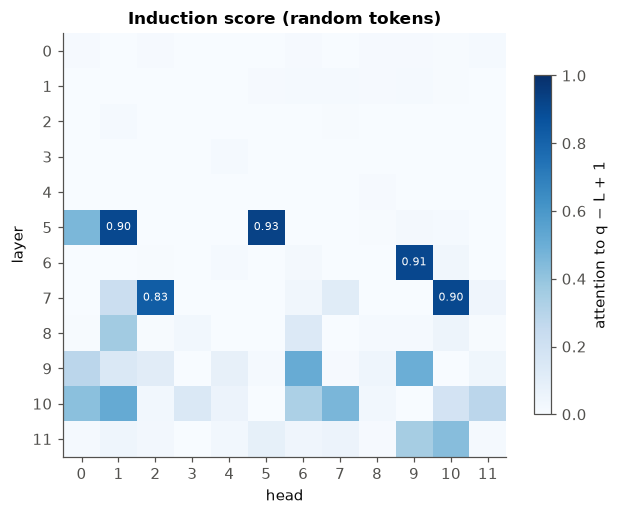

head  score
 5.5  0.930
 6.9  0.907
 5.1  0.905
7.10  0.905
 7.2  0.828
10.1  0.518
 9.6  0.510
 9.9  0.498
10.7  0.462
 5.0  0.460


In [3]:
rand_patterns = ind.attention_patterns(model, rand)
rand_scores = ind.induction_scores(rand_patterns, L)       # [layer, head]
TOP5 = ind.top_heads(rand_scores, 5)

def heatmap(ax, scores, title, vmax=1.0, annotate=5):
    im = ax.imshow(scores, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set(xlabel="head", ylabel="layer", title=title,
           xticks=range(scores.shape[1]), yticks=range(scores.shape[0]))
    ax.grid(False)
    for l, h in ind.top_heads(scores, annotate):
        v = scores[l, h].item()
        ax.text(h, l, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.5 * vmax else INK)
    return im

fig, ax = plt.subplots(figsize=(6.5, 5))
im = heatmap(ax, rand_scores, "Induction score (random tokens)")
fig.colorbar(im, ax=ax, shrink=0.8, label="attention to q − L + 1")
fig.savefig(FIG / "2_induction_scores_random.png"); plt.show()

top10 = ind.top_heads(rand_scores, 10)
print(pd.DataFrame({"head": [f"{l}.{h}" for l, h in top10],
                    "score": [round(rand_scores[l, h].item(), 3) for l, h in top10]}).to_string(index=False))
summary["top5_random"] = ind.fmt_heads(TOP5)

## 3. Ablation

Ablate the top-*k* induction heads and measure how much of the in-context gain (first-copy loss − second-copy loss)
disappears. Two kinds of ablation:

- **Mean ablation:** replace each head's output with its average output (over batch and position) on a **held-out**
  batch of random tokens (same distribution, different seed). The average is never computed on the batch being evaluated.
- **Zero ablation:** set the head's output to zero. Harsher: it also removes the head's constant contribution.

Control: the same number of randomly chosen heads, excluding the top 20 induction heads, 10 draws per *k*
(the same draws for both kinds of ablation).

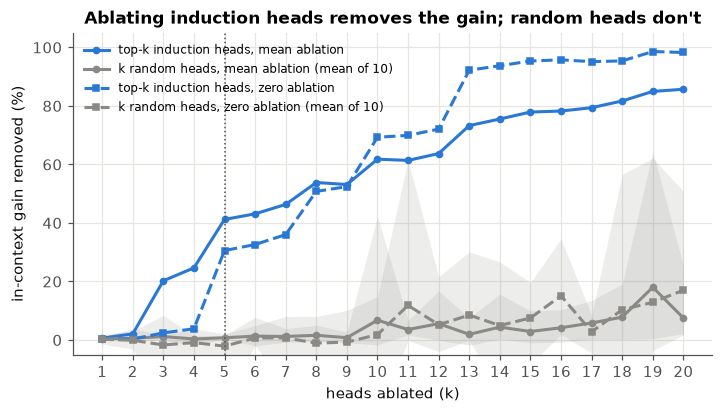

% of in-context gain removed:
        mean, same batch (previous method)  mean, held-out batch  zero
top 5                                 41.4                  41.2  30.6
top 10                                61.8                  61.8  69.3
top 20                                85.6                  85.7  98.3



one head at a time (% gain removed):
      mean, held-out  zero
5.5              0.6   0.2
6.9              1.5   0.1
5.1              5.7   4.7
7.10             0.2  -0.2
7.2              0.5   0.1
10.1             0.4  -0.1

5 random heads, mean ablation: 0.8% (range 0.3–1.6)
5 random heads, zero ablation: -2.1% (range -21.8–2.1)


In [4]:
rng = np.random.default_rng(SEED)
ranked = ind.top_heads(rand_scores, 20)
ks = list(range(1, 21))

rand_ref = ind.random_tokens(model, L, BATCH, SEED + 1)   # held-out batch, same distribution
REF_MEANS = ind.head_means(model, rand_ref)                 # [layer, head, d_head]
summary["config"]["heldout_seed"] = SEED + 1

def removed(heads, means):
    """% of the random-token gain removed; mean ablation with `means`, zero ablation if None."""
    return ind.gain_removed(rand_clean, ind.loss_summary(ind.ablated_loss(model, rand, heads, means), L))

draws = {k: [ind.random_heads(model, k, ranked, rng) for _ in range(N_RANDOM_DRAWS)] for k in ks}
curves = {}
for mode, means in [("mean", REF_MEANS), ("zero", None)]:
    curves[mode] = {
        "top": np.array([removed(ranked[:k], means) for k in ks]),
        "random": np.array([[removed(heads, means) for heads in draws[k]] for k in ks]),   # [k, draw]
    }

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for mode, ls, marker in [("mean", "-", "o"), ("zero", "--", "s")]:
    c = curves[mode]
    ax.plot(ks, c["top"] * 100, color=COLORS["en"], ls=ls, marker=marker, ms=4,
            label=f"top-k induction heads, {mode} ablation")
    ax.plot(ks, c["random"].mean(1) * 100, color=COLORS["random"], ls=ls, marker=marker, ms=4,
            label=f"k random heads, {mode} ablation (mean of {N_RANDOM_DRAWS})")
    ax.fill_between(ks, c["random"].min(1) * 100, c["random"].max(1) * 100, color=COLORS["random"], alpha=0.15, lw=0)
ax.axvline(5, color=MUTED, lw=1, ls=":")
ax.set(xlabel="heads ablated (k)", ylabel="in-context gain removed (%)", ylim=(-5, 105), xticks=ks,
       title="Ablating induction heads removes the gain; random heads don't")
ax.legend(frameon=False, loc="upper left", fontsize=8)
fig.savefig(FIG / "3_ablation_curve.png"); plt.show()

same_means = ind.head_means(model, rand)   # the previous method: means from the evaluated batch itself
cmp = pd.DataFrame({
    "mean, same batch (previous method)": [removed(ranked[:k], same_means) for k in (5, 10, 20)],
    "mean, held-out batch": [curves["mean"]["top"][k - 1] for k in (5, 10, 20)],
    "zero": [curves["zero"]["top"][k - 1] for k in (5, 10, 20)],
}, index=["top 5", "top 10", "top 20"]) * 100
print("% of in-context gain removed:"); print(cmp.round(1).to_string()); print()

single = pd.DataFrame({
    "mean, held-out": {f"{l}.{h}": removed([(l, h)], REF_MEANS) for l, h in ranked[:6]},
    "zero": {f"{l}.{h}": removed([(l, h)], None) for l, h in ranked[:6]},
}) * 100
print("one head at a time (% gain removed):"); print(single.round(1).to_string()); print()
for mode in ("mean", "zero"):
    r = curves[mode]["random"][4] * 100
    print(f"5 random heads, {mode} ablation: {r.mean():.1f}% (range {r.min():.1f}–{r.max():.1f})")

summary["ablation_random_tokens"] = {
    mode: {"top_k_removed": dict(zip(ks, curves[mode]["top"].tolist())),
           "random_k_removed_mean": dict(zip(ks, curves[mode]["random"].mean(1).tolist()))}
    for mode in curves
}
summary["ablation_random_tokens"]["same_batch_mean_previous_method"] = cmp.iloc[:, 0].to_dict()
summary["ablation_random_tokens"]["single_head_removed"] = single.to_dict()

## 4. Previous-token heads and K-composition

Induction needs a previous-token head upstream: it writes "the token before me was A" into each position,
which the induction head's keys then match against. Score heads by attention to *q − 1*, then mean-ablate (held-out means) the top
previous-token heads and check whether the induction heads lose their pattern.

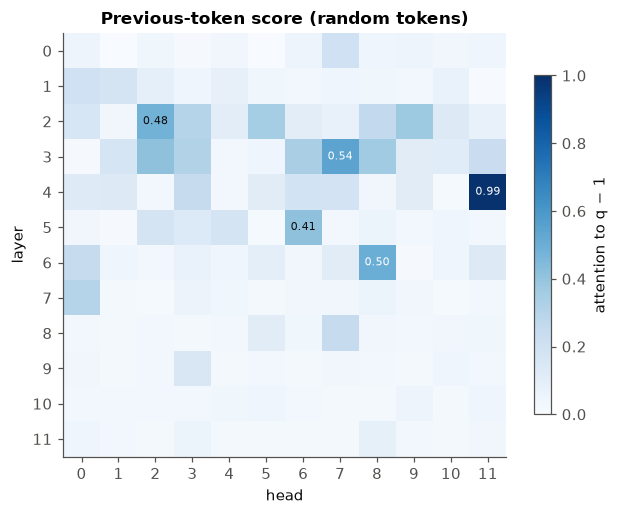

Induction scores of the top-5 induction heads:
      clean  ablate prev-token 4.11, 3.7, 6.8  ablate random early 3.1, 4.8, 1.11
5.5   0.930                             0.488                               0.928
6.9   0.907                             0.729                               0.903
5.1   0.905                             0.451                               0.883
7.10  0.905                             0.635                               0.909
7.2   0.828                             0.510                               0.833


In [5]:
prev_scores = ind.prev_token_scores(rand_patterns)
PREV3 = ind.top_heads(prev_scores, 3)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = heatmap(ax, prev_scores, "Previous-token score (random tokens)")
fig.colorbar(im, ax=ax, shrink=0.8, label="attention to q − 1")
fig.savefig(FIG / "4_prev_token_scores.png"); plt.show()

def induction_under(heads):
    hooks = ind.ablation_hooks(heads, REF_MEANS)   # held-out mean ablation
    with model.hooks(fwd_hooks=hooks):
        sc = ind.induction_scores(ind.attention_patterns(model, rand), L)
    return {f"{l}.{h}": round(sc[l, h].item(), 3) for l, h in TOP5}

early_pool = [(l, h) for l in range(5) for h in range(12) if (l, h) not in PREV3]
control3 = [early_pool[i] for i in rng.choice(len(early_pool), 3, replace=False)]
kcomp = pd.DataFrame({
    "clean": {f"{l}.{h}": round(rand_scores[l, h].item(), 3) for l, h in TOP5},
    f"ablate prev-token {ind.fmt_heads(PREV3)}": induction_under(PREV3),
    f"ablate random early {ind.fmt_heads(control3)}": induction_under(control3),
})
print("Induction scores of the top-5 induction heads:"); print(kcomp.to_string())
summary["prev_token_top3"] = ind.fmt_heads(PREV3)
summary["k_composition"] = kcomp.to_dict()

## 5. Extension: repeated natural text in four languages

Text: Articles 1–25 of the Universal Declaration of Human Rights (NLTK `udhr` corpus), the same content in
English, Spanish, German and Swedish.

**The confound.** GPT-2's BPE tokenizer was trained mostly on English. Non-English words break into many more
subword tokens, which changes two things at once:

1. *Sequence length.* The same article is 2–3× more tokens in Swedish than in English, and induction behaviour
   depends on the distance being copied over.
2. *What the "first copy" loss means.* Continuation tokens inside a word (`m|ä|nn|isk|or`) are often easy to
   predict even without repetition, so the first copy already looks easier and there is less left for
   induction to gain.

So a weaker number in Swedish would first of all be a tokenization effect, not evidence about how the model represents
Swedish. The analysis below reports the tokenizer statistics, then compares languages three ways:

- **5b. Matched text** (the naive version): each article repeated, whatever its token length.
- **5c. Matched token length** (the control): non-overlapping windows of exactly L = 50 tokens from each language.
  Loss is reported on all targets and on **word-initial targets only**, which removes the within-word confound.
  A **word-shuffled** variant removes grammar and any memorised UDHR text, so the first copy is hard in every
  language, like the random-token baseline.
- **5d. Robustness** across L = 25, 50, 100.

         words  tokens  tokens_per_word  continuation_share
English   1030    1166             1.13                0.12
Spanish   1108    2306             2.08                0.52
German     967    2697             2.79                0.64
Swedish    951    2616             2.75                0.64


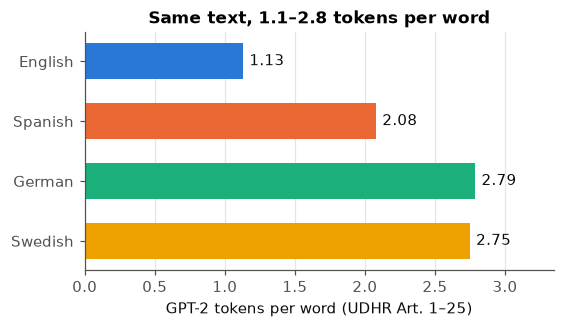

In [6]:
tok_stats = pd.DataFrame({lang: ind.tokenizer_stats(model, " ".join(ind.udhr_articles(lang))) for lang in ind.LANGS}).T
tok_stats.index = [ind.LANG_NAMES[l] for l in tok_stats.index]
tok_stats[["words", "tokens"]] = tok_stats[["words", "tokens"]].astype(int)
print(tok_stats.round(2).to_string())

fig, ax = plt.subplots(figsize=(5.5, 2.8))
bars = ax.barh(tok_stats.index[::-1], tok_stats["tokens_per_word"][::-1],
               color=[COLORS[l] for l in list(ind.LANGS)[::-1]], height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=4, color=INK)
ax.set(xlabel="GPT-2 tokens per word (UDHR Art. 1–25)", title="Same text, 1.1–2.8 tokens per word")
ax.grid(axis="y", visible=False); ax.set_xlim(0, tok_stats["tokens_per_word"].max() * 1.2)
fig.savefig(FIG / "5a_tokens_per_word.png"); plt.show()
summary["tokenizer"] = tok_stats.to_dict(orient="index")

### 5b. Matched text (naive comparison)

Each of the 25 articles repeated once, one sequence at a time. Same content, different token lengths.

In [7]:
def top5_score(scores):
    return float(np.mean([scores[l, h].item() for l, h in TOP5]))

rows = []
for lang in ind.LANGS:
    for i, art in enumerate(ind.udhr_articles(lang), start=1):
        seq = ind.tokenize(model, art)[None]
        Li = seq.shape[1]
        toks = ind.repeat(model, seq)
        s = ind.loss_summary(ind.per_token_loss(model, toks), Li)
        sc = ind.induction_scores(ind.attention_patterns(model, toks), Li)
        rows.append({"lang": ind.LANG_NAMES[lang], "article": i, "tokens": Li,
                     "first": s.first, "second": s.second, "gain": s.gain, "top5_induction": top5_score(sc)})
matched_text = pd.DataFrame(rows)
mt = matched_text.groupby("lang", sort=False)[["tokens", "first", "second", "gain", "top5_induction"]].mean()
print(mt.round(2).to_string())
summary["matched_text"] = mt.to_dict(orient="index")

         tokens  first  second  gain  top5_induction
lang                                                
English   46.64   2.81    0.20  2.61            0.67
Spanish   92.24   4.45    0.10  4.35            0.82
German   107.88   3.88    0.08  3.80            0.82
Swedish  104.64   5.28    0.11  5.17            0.83


### 5c. Matched token length (the control)

20 non-overlapping windows of exactly 50 tokens per language (English only has 23), each repeated once.
At 50 tokens a window spans roughly 44 English words but only about 18 Swedish ones; that difference is the point.
The same metrics are computed for the random-token batch as a reference.

**Mean ablation here uses two-fold cross-fitting.** The UDHR is too short to hold out a separate set of English
windows, so the 20 windows are split into two interleaved halves; each half is ablated with head means computed
on the other half. Every window is evaluated with means from windows it is not part of. The random-token row uses
the held-out batch from section 3.

In [8]:
N_WIN = 20

def evaluate(tokens, L, rng, ref_means=None):
    """Matched-length metrics. Mean ablation uses `ref_means` if given, else two-fold cross-fitting."""
    loss = ind.per_token_loss(model, tokens)
    clean = ind.loss_summary(loss, L)
    mask = ind.target_word_initial_mask(model, tokens)
    initial = ind.loss_summary(loss, L, mask)
    sc = ind.induction_scores(ind.attention_patterns(model, tokens), L)
    folds = None if ref_means is not None else ind.fold_means(model, tokens)

    def ablated(heads):
        loss = (ind.ablated_loss(model, tokens, heads, ref_means) if ref_means is not None
                else ind.crossfit_ablated_loss(model, tokens, heads, folds))
        return ind.loss_summary(loss, L)

    abl = ind.gain_removed(clean, ablated(TOP5))
    ctrl = np.mean([ind.gain_removed(clean, ablated(ind.random_heads(model, 5, ranked, rng)))
                    for _ in range(N_RANDOM_DRAWS)])
    return {
        "first": clean.first, "second": clean.second, "gain": clean.gain,
        "gain_word_initial": initial.gain,
        "top5_induction": top5_score(sc),
        "spearman_vs_random": spearmanr(sc.flatten(), rand_scores.flatten()).statistic,
        "own_top5": ind.fmt_heads(ind.top_heads(sc, 5)),
        "own_top5_overlap": len(set(ind.top_heads(sc, 5)) & set(TOP5)),
        "ablate_top5_removed": abl, "ablate_random5_removed": ctrl,
    }, sc

rng = np.random.default_rng(SEED)
results, lang_scores = {}, {}
for lang in ind.LANGS:
    text = " ".join(ind.udhr_articles(lang))
    for cond, t in [("natural", text), ("shuffled", ind.shuffle_words(text, SEED))]:
        r, sc = evaluate(ind.token_windows(model, t, L, N_WIN), L, rng)
        results[(ind.LANG_NAMES[lang], cond)] = r
        if cond == "natural":
            lang_scores[lang] = sc
results[("random tokens", "—")], _ = evaluate(rand, L, rng, ref_means=REF_MEANS)

matched_len = pd.DataFrame(results).T
matched_len.index.names = ["language", "text"]
pd.set_option("display.width", 200)
print(matched_len.round(2).to_string())
matched_len.round(4).to_csv(RES / "matched_length_L50.csv")
summary["matched_length_L50"] = {f"{a} / {b}": v for (a, b), v in results.items()}

                            first    second       gain gain_word_initial top5_induction spearman_vs_random                  own_top5 own_top5_overlap ablate_top5_removed ablate_random5_removed
language      text                                                                                                                                                                              
English       natural    3.002119  0.225756   2.776363          2.973787        0.68807           0.971767  5.1, 7.2, 7.10, 6.9, 5.5                5            0.333364               0.008769
              shuffled   7.291776  0.329715   6.962062          7.503963       0.779216           0.983679  5.1, 7.2, 6.9, 5.5, 7.10                5            0.411726               0.013438
Spanish       natural    4.652185  0.214938   4.437247          5.964238       0.833768           0.966393  5.1, 7.10, 7.2, 5.5, 6.9                5            0.451848               0.007562
              shuffled   4.991459  

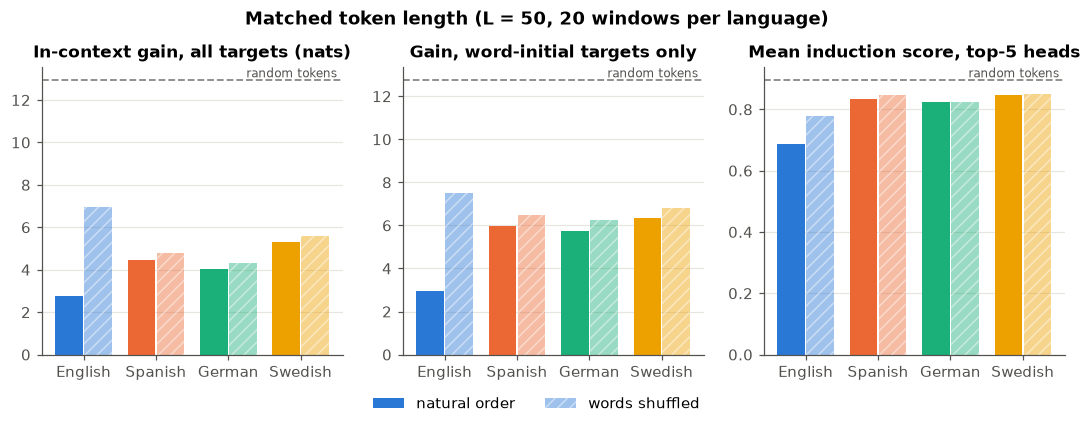

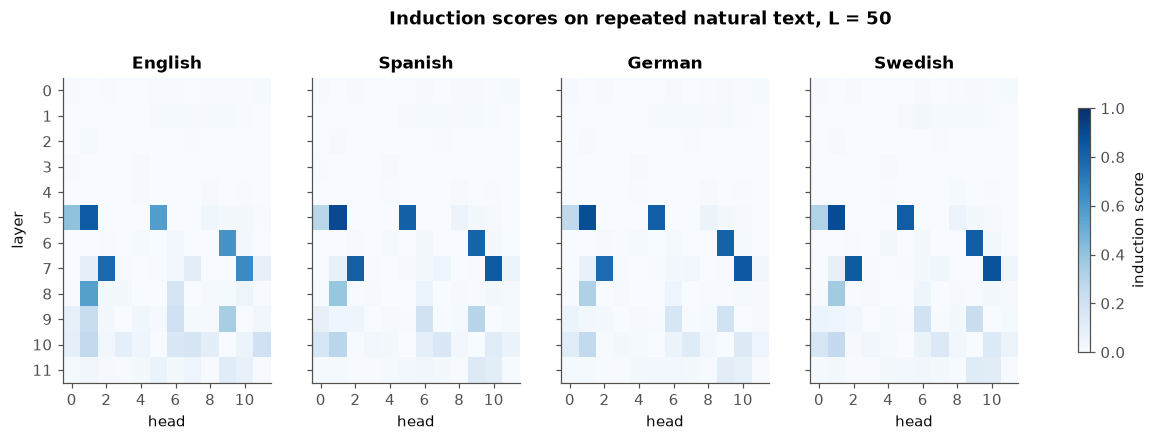

Spearman correlation of the 144 per-head induction scores between languages (natural text):
         English  Spanish  German  Swedish
English     1.00     0.98    0.97     0.98
Spanish     0.98     1.00    1.00     1.00
German      0.97     1.00    1.00     1.00
Swedish     0.98     1.00    1.00     1.00


In [9]:
langs = list(ind.LANGS)
names = [ind.LANG_NAMES[l] for l in langs]
metrics = [("gain", "In-context gain, all targets (nats)"),
           ("gain_word_initial", "Gain, word-initial targets only"),
           ("top5_induction", "Mean induction score, top-5 heads")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
x, w = np.arange(len(langs)), 0.38
for ax, (m, title) in zip(axes, metrics):
    nat = [matched_len.loc[(n, "natural"), m] for n in names]
    shf = [matched_len.loc[(n, "shuffled"), m] for n in names]
    ax.bar(x - w / 2 - 0.01, nat, w, color=[COLORS[l] for l in langs], label="natural order")
    ax.bar(x + w / 2 + 0.01, shf, w, color=[COLORS[l] for l in langs], alpha=0.45, hatch="///",
           edgecolor="white", lw=0, label="words shuffled")
    ref = matched_len.loc[("random tokens", "—"), m]
    ax.axhline(ref, color=COLORS["random"], ls="--", lw=1.2)
    ax.text(len(langs) - 0.5, ref, "random tokens", color=MUTED, fontsize=8, ha="right", va="bottom")
    ax.set_xticks(x, names); ax.set_title(title); ax.grid(axis="x", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Matched token length (L = 50, 20 windows per language)", y=1.03, fontweight="bold")
fig.savefig(FIG / "5c_matched_length.png"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, lang in zip(axes, langs):
    im = heatmap(ax, lang_scores[lang], ind.LANG_NAMES[lang], annotate=0)
    ax.set_xticks(range(0, 12, 2)); ax.label_outer()
fig.colorbar(im, ax=axes, shrink=0.8, label="induction score")
fig.suptitle("Induction scores on repeated natural text, L = 50", y=1.05, fontweight="bold")
fig.savefig(FIG / "5c_heatmaps_by_language.png"); plt.show()

print("Spearman correlation of the 144 per-head induction scores between languages (natural text):")
corr = pd.DataFrame({ind.LANG_NAMES[a]: {ind.LANG_NAMES[b]: spearmanr(lang_scores[a].flatten(), lang_scores[b].flatten()).statistic
                                         for b in langs} for a in langs})
print(corr.round(2).to_string())
summary["between_language_spearman"] = corr.to_dict()

### 5e. Why is English *lower*? Checking for split attention

On natural text a token can occur several times in the first copy (*the*, *of*, *and*), so several earlier
positions are valid induction targets and the strict score (only *q − L + 1*) undercounts. This counts
attention to **any** valid target and reports how often the target is ambiguous.

In [10]:
diag = {}
for lang in ind.LANGS:
    text = " ".join(ind.udhr_articles(lang))
    for cond, t in [("natural", text), ("shuffled", ind.shuffle_words(text, SEED))]:
        toks = ind.token_windows(model, t, L, N_WIN)
        P = ind.attention_patterns(model, toks)
        strict, any_t = ind.induction_scores(P, L), ind.any_target_induction_scores(P, toks, L)
        diag[(ind.LANG_NAMES[lang], cond)] = {
            "ambiguous_share": ind.ambiguous_share(toks, L),
            "top5_strict": top5_score(strict), "top5_any_target": top5_score(any_t)}
P = ind.attention_patterns(model, rand)
diag[("random tokens", "—")] = {"ambiguous_share": ind.ambiguous_share(rand, L),
                                "top5_strict": top5_score(rand_scores),
                                "top5_any_target": top5_score(ind.any_target_induction_scores(P, rand, L))}
diag = pd.DataFrame(diag).T
diag.index.names = ["language", "text"]
print(diag.round(2).to_string())
summary["split_attention_check"] = {f"{a} / {b}": v for (a, b), v in diag.to_dict(orient="index").items()}

                        ambiguous_share  top5_strict  top5_any_target
language      text                                                   
English       natural              0.44         0.69             0.73
              shuffled             0.40         0.78             0.82
Spanish       natural              0.30         0.83             0.88
              shuffled             0.23         0.85             0.88
German        natural              0.22         0.82             0.86
              shuffled             0.23         0.82             0.85
Swedish       natural              0.32         0.85             0.88
              shuffled             0.31         0.85             0.88
random tokens —                    0.00         0.89             0.89


### 5d. Robustness across window length

Same matched-length analysis at L = 25, 50 and 100 (10 windows each, the most English allows at L = 100).

In [11]:
rob = {}
for Lr in [25, 50, 100]:
    for lang in ind.LANGS:
        text = " ".join(ind.udhr_articles(lang))
        for cond, t in [("natural", text), ("shuffled", ind.shuffle_words(text, SEED))]:
            toks = ind.token_windows(model, t, Lr, 10)
            loss = ind.per_token_loss(model, toks)
            s = ind.loss_summary(loss, Lr)
            si = ind.loss_summary(loss, Lr, ind.target_word_initial_mask(model, toks))
            sc = ind.induction_scores(ind.attention_patterns(model, toks), Lr)
            rob[(Lr, ind.LANG_NAMES[lang], cond)] = {"gain": s.gain, "gain_word_initial": si.gain, "top5_induction": top5_score(sc)}
robust = pd.DataFrame(rob).T
robust.index.names = ["L", "language", "text"]
print(robust.unstack("L").round(2).to_string())
robust.round(4).to_csv(RES / "robustness_L.csv")

                   gain             gain_word_initial             top5_induction            
L                   25    50    100               25    50    100            25    50    100
language text                                                                               
English  natural   2.71  2.66  2.54              2.99  2.87  2.70           0.63  0.70  0.70
         shuffled  7.17  7.03  6.73              7.92  7.61  7.26           0.76  0.78  0.78
German   natural   4.03  4.01  3.85              5.77  5.92  5.71           0.78  0.82  0.84
         shuffled  4.16  4.22  4.24              5.65  6.22  6.36           0.75  0.82  0.84
Spanish  natural   4.18  4.20  4.21              5.92  5.99  5.81           0.80  0.82  0.82
         shuffled  5.09  4.92  4.73              6.46  6.53  6.55           0.81  0.85  0.87
Swedish  natural   5.24  5.16  5.04              5.89  6.07  6.25           0.80  0.84  0.85
         shuffled  5.77  5.60  5.37              6.86  6.83  6.69     

In [12]:
with open(RES / "summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
print("saved", RES / "summary.json")

saved results/summary.json
